# Обучение моделей и сравнение. Первое приближение для предварительной оценки

In [2]:
# 1. Загрузка данных
train_df = pd.read_csv('train_features_final.csv')
test_df = pd.read_csv('test_features_final.csv')

# 2. Отбор признаков на основе анализа
# Исключаем ID, таргет, даты и признаки с критическим дисбалансом/коллинеарностью
features_to_drop = ['user_id', 'shift_id', 'target', 'start_at', 'location_id_shift', 'employer_id', 'location_id_user', 'task_type', 'date', 'task_category',
    'shift_time_of_day', 'is_short_shift', 'is_weekday', 'shift_day_of_week']

# Для деревянных моделей мультиколлинеарность менее критична, но удалим самые явные дубли
# чтобы модель была компактнее
duplicate_features = [
    'user_total_successful_actions',                    # заменяем на success_rate
    'reward',                                           # заменяем на reward_per_hour
    'mk_match',                                         # заменяем на mk_match_2
    'user_active_days'                                  # заменяем на total_views
]

final_drop = features_to_drop + duplicate_features
X_train = train_df.drop(columns=[col for col in final_drop if col in train_df.columns])
y_train = train_df['target']

X_test = test_df.drop(columns=[col for col in final_drop if col in test_df.columns])
y_test = test_df['target']

print(f"Используется признаков: {X_train.shape[1]}")

# 3. Определение моделей
models = {
    "Decision Tree": DecisionTreeClassifier(max_depth=10, random_state=42, class_weight='balanced'),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1, class_weight='balanced'),
    "XGBoost": XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, use_label_encoder=False, eval_metric='logloss')
}

# 4. Цикл обучения и оценки
for name, model in models.items():
    print(f"\n\n    Модель {name}")
    start_time = time.time()

    # Обучение
    model.fit(X_train, y_train)

    # Предсказание
    train_pred = model.predict(X_train)
    train_proba = model.predict_proba(X_train)[:, 1]

    test_pred = model.predict(X_test)
    test_proba = model.predict_proba(X_test)[:, 1]

    duration = time.time() - start_time

    # Вывод метрик
    print(f"Время обучения: {duration:.2f} сек")
    print("\nМетрики на train:")
    print(classification_report(y_train, train_pred))
    print(f"ROC-AUC Train: {roc_auc_score(y_train, train_proba):.4f}")

    print("\nМетрики на Test:")
    print(classification_report(y_test, test_pred))
    print(f"ROC-AUC Test: {roc_auc_score(y_test, test_proba):.4f}")

    # Важность признаков (Топ-5)
    if hasattr(model, 'feature_importances_'):
        importances = pd.Series(model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
        print("\nТОП-5 важных признаков:")
        print(importances.head(5))

Используется признаков: 44


    Модель Decision Tree
Время обучения: 1.09 сек

Метрики на train:
              precision    recall  f1-score   support

           0       1.00      0.88      0.94    221025
           1       0.15      0.93      0.26      4946

    accuracy                           0.88    225971
   macro avg       0.57      0.91      0.60    225971
weighted avg       0.98      0.88      0.92    225971

ROC-AUC Train: 0.9704

Метрики на Test:
              precision    recall  f1-score   support

           0       1.00      0.89      0.94    217008
           1       0.12      0.81      0.21      4108

    accuracy                           0.89    221116
   macro avg       0.56      0.85      0.57    221116
weighted avg       0.98      0.89      0.92    221116

ROC-AUC Test: 0.8936

ТОП-5 важных признаков:
user_success_rate       0.415122
view_count_for_shift    0.208864
has_apply_before        0.188797
user_total_views        0.032896
reward_per_hour         0.0321

C:\Users\arnt\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\xgboost\training.py:200: UserWarning: [12:27:14] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Время обучения: 0.91 сек

Метрики на train:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99    221025
           1       0.98      0.46      0.63      4946

    accuracy                           0.99    225971
   macro avg       0.98      0.73      0.81    225971
weighted avg       0.99      0.99      0.99    225971

ROC-AUC Train: 0.9740

Метрики на Test:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99    217008
           1       0.94      0.41      0.57      4108

    accuracy                           0.99    221116
   macro avg       0.97      0.70      0.78    221116
weighted avg       0.99      0.99      0.99    221116

ROC-AUC Test: 0.9536

ТОП-5 важных признаков:
has_apply_before             0.631774
view_count_for_shift         0.116414
user_success_rate            0.074782
user_employer_experience     0.014323
user_task_type_experience    0.011758
dtype: float32


### **Сравнение базовых моделей**

| Модель | Test ROC-AUC | Test Recall | Test Precision | Особенности |
| :--- | :---: | :---: | :---: | :--- |
| **Decision Tree** | 0.8936 | **0.81** | 0.12 | Склонна к переобучению, высокий Recall за счет балансировки весов. |
| **Random Forest** | 0.9469 | 0.76 | 0.18 | Стабильный ансамбль, хороший баланс между метриками. |
| **XGBoost** | **0.9536** | 0.41 | **0.94** | Максимальная точность (минимум ложных тревог), но пропускает часть целевых событий. |

**Краткий вывод:**
- Если нам критично **найти как можно больше потенциальных записей** (Recall), лучше использовать сбалансированное Дерево или Случайный лес.
- Если нам нужно **безошибочно определять запись** (Precision), XGBoost - абсолютный лидер.

In [30]:
# !pip install catboost

In [3]:
strict_drop = ['user_id', 'shift_id', 'target', 'start_at', 'location_id_shift', 'employer_id', 'location_id_user', 'task_type', 'date', 'task_category',
    'shift_time_of_day', 'is_short_shift', 'is_weekday', 'shift_day_of_week']

# Набор 2: Расширенный (Extended)
extended_drop = ['user_id', 'shift_id', 'target', 'start_at', 'employer_id', 'location_id_user', 'date']

# 1. Определение наборов признаков
# Набор 1: Жестко ограниченный (Strict)
strict_drop = ['user_id', 'shift_id', 'target', 'start_at', 'location_id_shift', 'employer_id', 'location_id_user', 'task_type', 'date', 'task_category',
    'shift_time_of_day', 'is_short_shift', 'is_weekday', 'shift_day_of_week']

# Набор 2: Расширенный (Extended)
extended_drop = ['user_id', 'shift_id', 'target', 'start_at', 'employer_id', 'location_id_user', 'date']

def get_datasets(train, test, drop_cols):
    # Удаляем дубликаты, выявленные анализом VIF, если они есть в списке
    vif_duplicates = ['user_total_successful_actions', 'reward', 'mk_match', 'user_active_days']
    final_drop = drop_cols + [c for c in vif_duplicates if c not in drop_cols]

    x_train = train.drop(columns=[c for c in final_drop if c in train.columns])
    x_test = test.drop(columns=[c for c in final_drop if c in test.columns])
    return x_train, x_test

def run_benchmark(models_dict, train_data, test_data, feature_sets):
    results = []
    for set_name, drop_list in feature_sets.items():
        X_tr, X_te = get_datasets(train_data, test_data, drop_list)
        y_tr, y_te = train_data['target'], test_data['target']

        for model_name, model in models_dict.items():
            start = time.time()
            # Обработка категорий для бустингов
            X_tr_proc = X_tr.copy()
            X_te_proc = X_te.copy()
            cat_cols = X_tr_proc.select_dtypes(include=['object']).columns.tolist()

            if "LogReg" in model_name:
                model.fit(X_tr_proc, y_tr)
            elif "CatBoost" in model_name:
                model.fit(X_tr_proc, y_tr, cat_features=cat_cols, verbose=False)
            else:
                for col in cat_cols:
                    X_tr_proc[col] = pd.Categorical(X_tr_proc[col]).codes
                    X_te_proc[col] = pd.Categorical(X_te_proc[col]).codes
                model.fit(X_tr_proc, y_tr)

            probas = model.predict_proba(X_te_proc)[:, 1]
            preds = (probas > 0.5).astype(int)

            results.append({
                "Feature_Set": set_name,
                "Model": model_name,
                "ROC-AUC": roc_auc_score(y_te, probas),
                "Recall": recall_score(y_te, preds),
                "Precision": precision_score(y_te, preds, zero_division=0),
                "Duration": time.time() - start
            })
    return pd.DataFrame(results)

### Группа 1: Деревянные модели (Decision Tree & Random Forest)

In [32]:
!pip install jinja2


[notice] A new release of pip is available: 25.0.1 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
tree_models = {
    "Decision Tree (Bal)": DecisionTreeClassifier(max_depth=10, random_state=42, class_weight='balanced'),
    "Random Forest (Bal)": RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1, class_weight='balanced')
}

feature_sets = {"Strict": strict_drop, "Extended": extended_drop}
tree_results = run_benchmark(tree_models, train_df, test_df, feature_sets)
display(tree_results.style.background_gradient(cmap='viridis', subset=['ROC-AUC', 'Recall']))

,Feature_Set,Model,ROC-AUC,Recall,Precision,Duration
0,Strict,Decision Tree (Bal),0.893599,0.812317,0.119997,1.044983
1,Strict,Random Forest (Bal),0.946912,0.764849,0.177846,2.061858
2,Extended,Decision Tree (Bal),0.893801,0.805501,0.121610,1.291650
3,Extended,Random Forest (Bal),0.946799,0.763875,0.176332,2.343437


### Группа 2: Boosting модели (XGBoost, LightGBM, CatBoost)

In [5]:
boosting_models = {
    "XGBoost": XGBClassifier(n_estimators=100, max_depth=6, random_state=42, eval_metric='logloss'),
    "LightGBM Balanced": lgb.LGBMClassifier(n_estimators=100, is_unbalance=True, random_state=42, n_jobs=-1, verbose=-1),
    "CatBoost Weighted": CatBoostClassifier(iterations=200, auto_class_weights='Balanced', random_seed=42, verbose=False)
}

boost_results = run_benchmark(boosting_models, train_df, test_df, feature_sets)
display(boost_results.style.background_gradient(cmap='plasma', subset=['ROC-AUC', 'Recall']))

,Feature_Set,Model,ROC-AUC,Recall,Precision,Duration
0,Strict,XGBoost,0.950295,0.428189,0.875560,0.644142
1,Strict,LightGBM Balanced,0.952104,0.826193,0.150310,0.935587
2,Strict,CatBoost Weighted,0.932988,0.732473,0.191096,2.566796
3,Extended,XGBoost,0.950665,0.432814,0.842654,0.730369
4,Extended,LightGBM Balanced,0.953199,0.832522,0.152665,1.052800
5,Extended,CatBoost Weighted,0.936990,0.744645,0.199635,11.681828


### Группа 3: Линейные модели (Logistic Regression)

In [6]:
def get_lr_pipeline(X):
    num_cols = X.select_dtypes(exclude=['object']).columns.tolist()
    cat_cols = X.select_dtypes(include=['object']).columns.tolist()
    return Pipeline([
        ('pre', ColumnTransformer([
            ('num', StandardScaler(), num_cols),
            ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
        ])),
        ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
    ])

# Manual loop for LR as it needs different pipelines per feature set
lr_results = []
for set_name, drop_list in feature_sets.items():
    X_tr, X_te = get_datasets(train_df, test_df, drop_list)
    pipe = get_lr_pipeline(X_tr)
    start = time.time()
    pipe.fit(X_tr, train_df['target'])
    probas = pipe.predict_proba(X_te)[:, 1]
    preds = (probas > 0.5).astype(int)
    lr_results.append({
        "Feature_Set": set_name, "Model": "LogReg (Bal)",
        "ROC-AUC": roc_auc_score(test_df['target'], probas),
        "Recall": recall_score(test_df['target'], preds),
        "Precision": precision_score(test_df['target'], preds, zero_division=0),
        "Duration": time.time() - start
    })

lr_results_df = pd.DataFrame(lr_results)
display(lr_results_df.style.background_gradient(cmap='magma'))

,Feature_Set,Model,ROC-AUC,Recall,Precision,Duration
0,Strict,LogReg (Bal),0.943509,0.927702,0.077880,1.501292
1,Extended,LogReg (Bal),0.944633,0.872931,0.105922,2.854333


### Финальная оценка всех алгоритмов и наборов параметров

In [7]:
full_summary = pd.concat([tree_results, boost_results, lr_results_df], ignore_index=True)
final_comparison = full_summary.sort_values(["Feature_Set", "ROC-AUC"], ascending=[True, False])

print("Финальная сводная таблица сравнения")
display(final_comparison.pivot_table(
    index="Model",
    columns="Feature_Set",
    values=["ROC-AUC", "Recall", "Precision"]
).style.highlight_max(axis=0, color='lightgreen'))

Финальная сводная таблица сравнения


### Анализ важности признаков

Определили наиболее эффективные модели, теперь поссмотрим, какие признаки вносят наибольший вклад. Будем использовать модель **LightGBM Balanced** на наборе функций **Extended**, чтобы определить ключевые факторы вовлеченности пользователей.

C:\Users\arnt\AppData\Local\Temp\ipykernel_18072\2031989895.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feat_imp.head(20), palette='viridis')


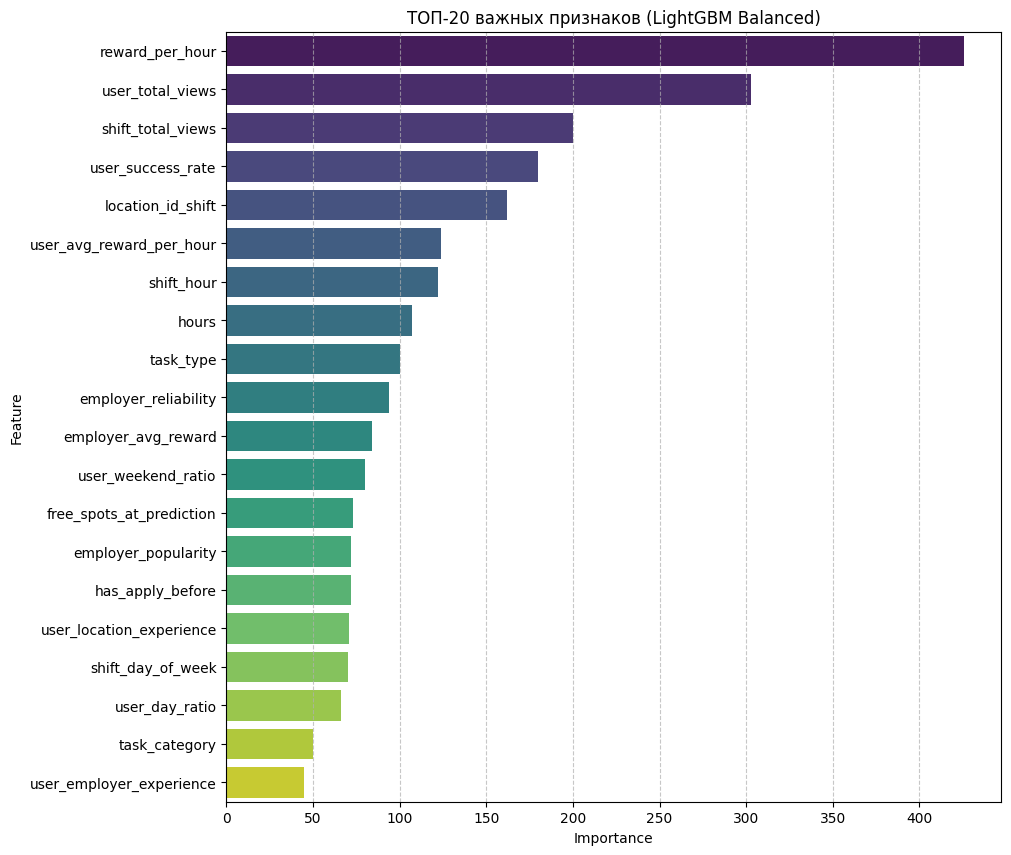

In [8]:
# 1. Подготовка данных (расширенный набор)
X_tr_ext, X_te_ext = get_datasets(train_df, test_df, extended_drop)
y_tr = train_df['target']

# 2. Обучение лучшей (LightGBM)
best_model = lgb.LGBMClassifier(n_estimators=100, is_unbalance=True, random_state=42, n_jobs=-1, verbose=-1)

# Категории процессов LightGBM
X_tr_ext_proc = X_tr_ext.copy()
cat_cols = X_tr_ext_proc.select_dtypes(include=['object']).columns.tolist()
for col in cat_cols:
    X_tr_ext_proc[col] = pd.Categorical(X_tr_ext_proc[col]).codes

best_model.fit(X_tr_ext_proc, y_tr)

# 3. Вывод важности
feat_imp = pd.DataFrame({
    'Feature': X_tr_ext.columns,
    'Importance': best_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 10))
sns.barplot(x='Importance', y='Feature', data=feat_imp.head(20), palette='viridis')
plt.title('ТОП-20 важных признаков (LightGBM Balanced)')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

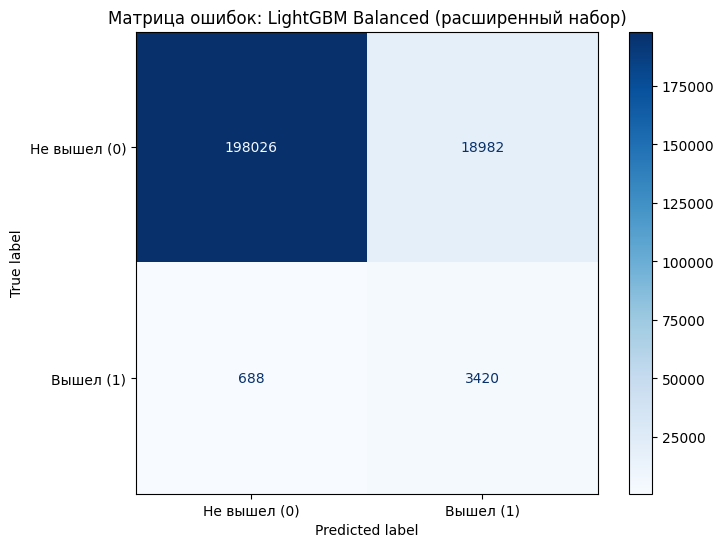

In [9]:
# 1. Получение прогнозов для лучшего результата
# Мы используем обработанный расширенный тестовый набор из предыдущих шагов
# Предполагается, что best_model и X_te_ext доступны из предыдущих ячеек
X_te_ext_proc = X_te_ext.copy()
cat_cols = X_te_ext_proc.select_dtypes(include=['object']).columns.tolist()
for col in cat_cols:
    X_te_ext_proc[col] = pd.Categorical(X_te_ext_proc[col]).codes

y_pred = best_model.predict(X_te_ext_proc)

# 2. Матрица ошибок
cm = confusion_matrix(y_test, y_pred)

# 3. Вывод
fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Не вышел (0)', 'Вышел (1)'])
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title('Матрица ошибок: LightGBM Balanced (расширенный набор)')
plt.grid(False)
plt.show()

Оптимальный порог: 0.9414
Max F1-Score: 0.5785
Precision на оптимальном пороге: 0.8700
Recall на оптимальном пороге: 0.4333


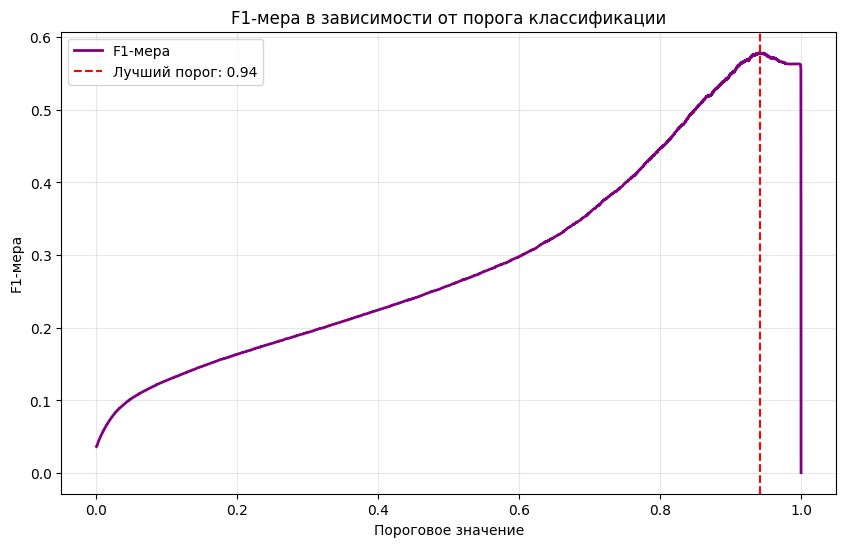

In [10]:
# 1. Вероятностные оценки для тестового набора данных модели с наилучшими показателями
y_scores = best_model.predict_proba(X_te_ext_proc)[:, 1]

# 2. Расчет precision, recall и thresholds
precision, recall, thresholds = precision_recall_curve(y_test, y_scores)

# 3. F1-мера для каждого порогового значения
# Обрабатываем возможное деление через np.divide с условием where
f1_scores = np.divide(2 * precision * recall, precision + recall, out=np.zeros_like(precision), where=(precision + recall) != 0)

# 4. Пороговое значение, обеспечивающее максимальное значение F1-меры
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 1.0
best_f1 = f1_scores[best_idx]

print(f'Оптимальный порог: {best_threshold:.4f}')
print(f'Max F1-Score: {best_f1:.4f}')
print(f'Precision на оптимальном пороге: {precision[best_idx]:.4f}')
print(f'Recall на оптимальном пороге: {recall[best_idx]:.4f}')

# 5. F1-мера против порогового значения
plt.figure(figsize=(10, 6))
plt.plot(thresholds, f1_scores[:-1], color='purple', lw=2, label='F1-мера')
plt.axvline(best_threshold, color='red', linestyle='--', label=f'Лучший порог: {best_threshold:.2f}')
plt.xlabel('Пороговое значение')
plt.ylabel('F1-мера')
plt.title('F1-мера в зависимости от порога классификации')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Результаты оценки порогового значения

Максимизируя F1-меру, мы определяем пороговое значение, которое уравновешивает стоимость пропуска работника (ложноотрицательный результат) со стоимостью отправки ложного уведомления (ложноположительный результат).

Далее мы можем применить это оптимальное пороговое значение для создания итогового отчета о классификации и матрицы ошибок, чтобы увидеть реальное влияние на наши показатели точности.

Финальный отчет по классификации (порог = 0.9414):
              precision    recall  f1-score   support

           0       0.99      1.00      0.99    217008
           1       0.87      0.43      0.58      4108

    accuracy                           0.99    221116
   macro avg       0.93      0.72      0.79    221116
weighted avg       0.99      0.99      0.99    221116



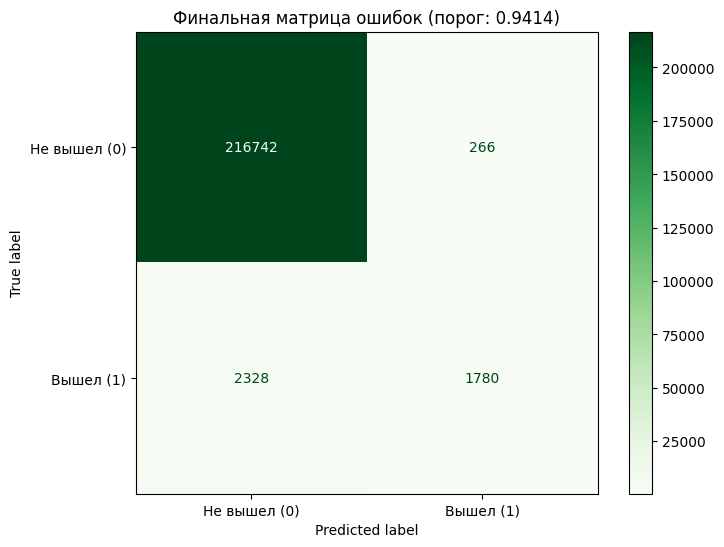

Финальная точность (precision): 0.8700
Финальная полнота (recall): 0.4333


In [11]:
# 1. Применяем оптимальный порог к вероятностям
# используем y_scores (вероятности) от лучшей модели LightGBM
final_threshold = 0.9414
y_pred_optimal = (y_scores >= final_threshold).astype(int)

# 2. Генерируем и выводим отчет по классификации
print("Финальный отчет по классификации (порог = 0.9414):")
print(classification_report(y_test, y_pred_optimal))

# 3. Считаем и строим финальную матрицу ошибок
final_cm = confusion_matrix(y_test, y_pred_optimal)

fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=final_cm, display_labels=['Не вышел (0)', 'Вышел (1)'])
disp.plot(cmap='Greens', ax=ax, values_format='d')
plt.title(f'Финальная матрица ошибок (порог: {final_threshold})')
plt.grid(False)
plt.show()

# Считаем точность и полноту для документации
tn, fp, fn, tp = final_cm.ravel()
precision_final = tp / (tp + fp)
recall_final = tp / (tp + fn)

print(f"Финальная точность (precision): {precision_final:.4f}")
print(f"Финальная полнота (recall): {recall_final:.4f}")

### Анализ влияния признаков через SHAP

Стандартная важность признаков показывает какие признаки модель использовала чаще всего, но не объясняет **как именно** они повлияли на результат. SHAP-значения позволяют это понять. Например, можно выяснить - повышает ли более высокая почасовая оплата вероятность записи на смену, или существует определённый порог после которого её влияние перестаёт расти.

C:\Users\arnt\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\shap\explainers\_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


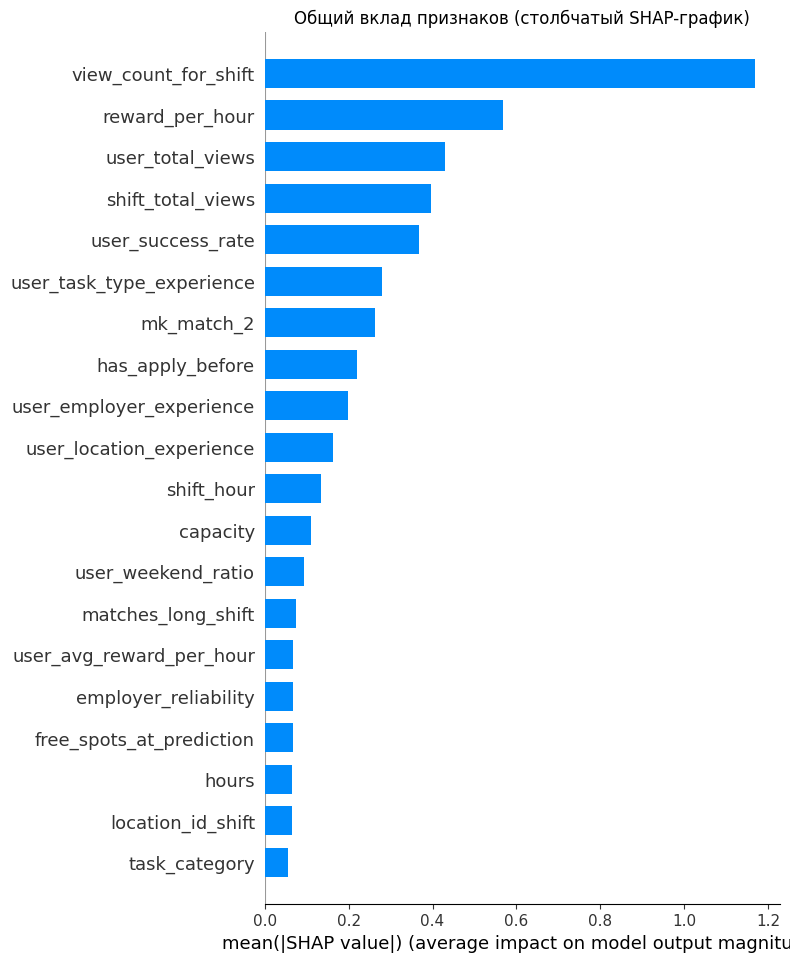

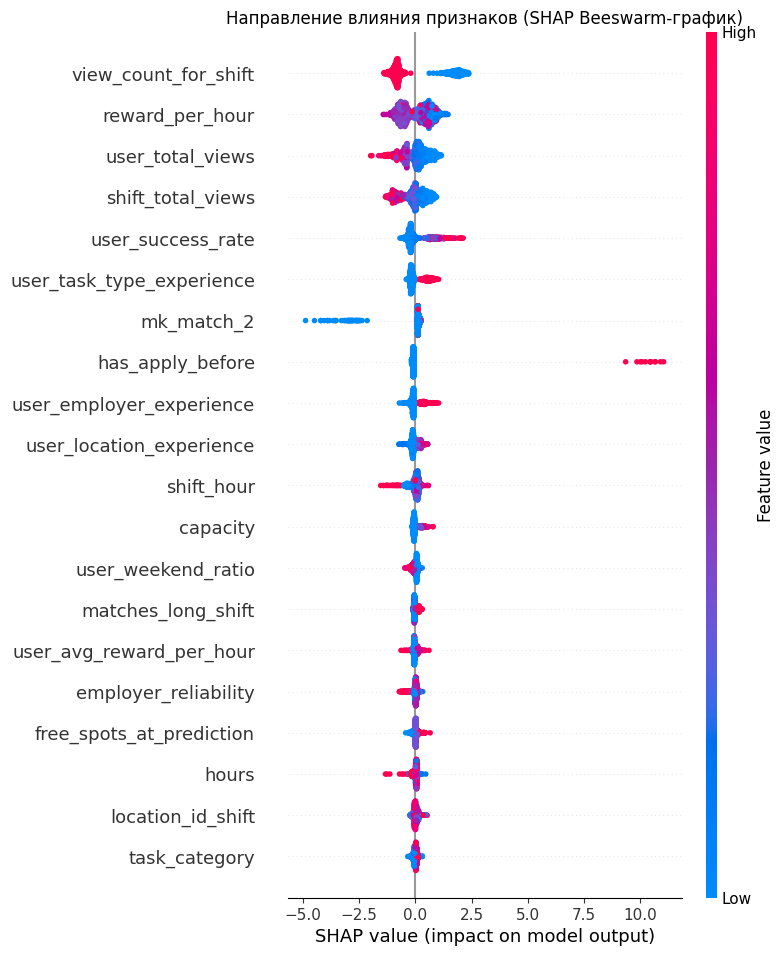

In [12]:
# Инициализируем SHAP-объяснитель
# используем подвыборку данных для ускорения расчёта
explainer = shap.TreeExplainer(best_model)
sample_data = X_te_ext_proc.sample(1000, random_state=42)
shap_values = explainer.shap_values(sample_data)

# Столбчатый график общего вклада признаков
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, sample_data, plot_type="bar", show=False)
plt.title('Общий вклад признаков (столбчатый SHAP-график)')
plt.show()

# Точечный график направления влияния признаков (beeswarm)
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, sample_data, show=False)
plt.title('Направление влияния признаков (SHAP Beeswarm-график)')
plt.show()

### Анализ важности признаков

Теперь, когда лучшие модели определены, посмотрим какие признаки вносят наибольший вклад в предсказания. Используем модель **LightGBM Balanced** на **расширенном** наборе признаков чтобы выявить ключевые факторы влияющие на запись пользователей на смену.

In [42]:
!pip install optuna


[notice] A new release of pip is available: 25.0.1 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


### Подбор гиперпараметров с помощью Optuna

Остановимся на оптимизации модели **LightGBM Balanced** как наиболее эффективной по результатам сравнения. 

Будем искать оптимальные значения для параметров `learning_rate`, `num_leaves`, `feature_fraction` и `bagging_fraction`.

In [13]:
# Подготовка данных для Optuna (расширенный набор признаков)
X_tr_opt, X_te_opt = get_datasets(train_df, test_df, extended_drop)
y_tr, y_te = train_df['target'], test_df['target']

# Кодируем категориальные признаки
cat_cols = X_tr_opt.select_dtypes(include=['object']).columns.tolist()
for col in cat_cols:
    X_tr_opt[col] = pd.Categorical(X_tr_opt[col]).codes
    X_te_opt[col] = pd.Categorical(X_te_opt[col]).codes

def objective(trial):
    param = {
        'objective': 'binary',
        'metric': 'auc',
        'verbosity': -1,
        'boosting_type': 'gbdt',
        'is_unbalance': True,                                                       # учитываем дисбаланс классов
        'random_state': 42,
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 20, 3000),
        'max_depth': trial.suggest_int('max_depth', 3, 12),
        'feature_fraction': trial.suggest_float('feature_fraction', 0.4, 1.0),
        'bagging_fraction': trial.suggest_float('bagging_fraction', 0.4, 1.0),
        'bagging_freq': trial.suggest_int('bagging_freq', 1, 7),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 100),
    }

    gbm = lgb.LGBMClassifier(**param)
    gbm.fit(X_tr_opt, y_tr)
    preds = gbm.predict_proba(X_te_opt)[:, 1]                                       # вероятности для положительного класса
    auc = roc_auc_score(y_te, preds)
    return auc

study = optuna.create_study(direction='maximize')                                   # максимизируем ROC-AUC
study.optimize(objective, n_trials=400)                                             # запускаем 400 испытаний

print('Количество завершённых испытаний:', len(study.trials))
print('Лучшие параметры:', study.best_trial.params)

[I 2026-05-17 12:28:36,361] A new study created in memory with name: no-name-484915b0-88dd-491e-9306-0c77ec362302
[I 2026-05-17 12:28:38,737] Trial 0 finished with value: 0.8790682923952351 and parameters: {'learning_rate': 0.2942903275677442, 'num_leaves': 51, 'max_depth': 6, 'feature_fraction': 0.482880290599189, 'bagging_fraction': 0.4281292226688656, 'bagging_freq': 2, 'min_child_samples': 18}. Best is trial 0 with value: 0.8790682923952351.
[I 2026-05-17 12:28:39,781] Trial 1 finished with value: 0.9538622293374903 and parameters: {'learning_rate': 0.06082668101062179, 'num_leaves': 1058, 'max_depth': 5, 'feature_fraction': 0.8980248847170574, 'bagging_fraction': 0.6782376788428621, 'bagging_freq': 3, 'min_child_samples': 94}. Best is trial 1 with value: 0.9538622293374903.
[I 2026-05-17 12:28:41,997] Trial 2 finished with value: 0.8598024843636043 and parameters: {'learning_rate': 0.2775577314102618, 'num_leaves': 1308, 'max_depth': 8, 'feature_fraction': 0.5308692287450804, 'bag

Количество завершённых испытаний: 400
Лучшие параметры: {'learning_rate': 0.08845033704079258, 'num_leaves': 1429, 'max_depth': 5, 'feature_fraction': 0.5922073403079874, 'bagging_fraction': 0.9974537328168589, 'bagging_freq': 1, 'min_child_samples': 93}


### Оценка оптимизированной модели

Переобучаем модель с лучшими параметрами найденными Optuna и сравниваем её результаты с базовой моделью.

пропустить ячейку ниже если запускали оптуну!

In [14]:
X_tr_opt, X_te_opt = get_datasets(train_df, test_df, extended_drop)
y_tr, y_te = train_df['target'], test_df['target']

# Кодируем категориальные признаки
cat_cols = X_tr_opt.select_dtypes(include=['object']).columns.tolist()
for col in cat_cols:
    X_tr_opt[col] = pd.Categorical(X_tr_opt[col]).codes                           # кодируем train
    X_te_opt[col] = pd.Categorical(X_te_opt[col]).codes                           # кодируем test

# Лучшие параметры найденные Optuna
best_params = {'learning_rate': 0.08306314256806901, 'num_leaves': 2037, 'max_depth': 6, 'feature_fraction': 0.7118453851902156, 'bagging_fraction': 0.8125337048543306, 'bagging_freq': 5, 'min_child_samples': 66}

In [15]:
# best_params = study.best_trial.params  # раскомментировать если запускали Optuna
best_params['objective'] = 'binary'
best_params['metric'] = 'auc'
best_params['is_unbalance'] = True                                                  # учитываем дисбаланс классов
best_params['random_state'] = 42
best_params['verbosity'] = -1                                                       # отключаем лишние логи

final_model = lgb.LGBMClassifier(**best_params)
final_model.fit(X_tr_opt, y_tr)

# Финальная оценка модели
final_probas = final_model.predict_proba(X_te_opt)[:, 1]                            # вероятности для положительного класса
final_auc = roc_auc_score(y_te, final_probas)

print(f'ROC-AUC оптимизированной модели: {final_auc:.4f}')

# Сравниваем с базовой моделью (LightGBM Extended из сравнения моделей ~0.9532)
baseline_auc = 0.9532
print(f'Улучшение: {final_auc - baseline_auc:.4f}')

ROC-AUC оптимизированной модели: 0.9556
Улучшение: 0.0024


In [16]:
X_tr_opt.columns

Index(['location_id_shift', 'task_type', 'need_mk', 'hours', 'capacity',
       'reward_per_hour', 'is_strict_location', 'has_mk', 'median_pay_window',
       'is_high_paid_window', 'is_long_shift', 'is_short_shift', 'mk_match_2',
       'location_match', 'shift_day_of_week', 'shift_hour',
       'shift_time_of_day', 'is_weekday', 'task_category', 'user_total_views',
       'user_success_rate', 'user_unique_employers', 'user_unique_task_types',
       'user_location_experience', 'user_high_paid_ratio',
       'user_long_shift_ratio', 'user_short_shift_ratio',
       'user_avg_reward_per_hour', 'user_successful_actions_last_7d',
       'user_successful_actions_last_14d', 'user_task_type_experience',
       'user_employer_experience', 'employer_avg_reward',
       'employer_popularity', 'employer_reliability', 'shift_total_views',
       'free_spots_at_prediction', 'is_full_at_prediction',
       'view_count_for_shift', 'has_apply_before', 'user_weekend_ratio',
       'user_day_ratio', '

### Важность признаков финальной оптимизированной модели

Анализируем важность признаков для лучшей модели чтобы понять какие факторы наиболее сильно влияют на предсказание записи пользователей на смену.

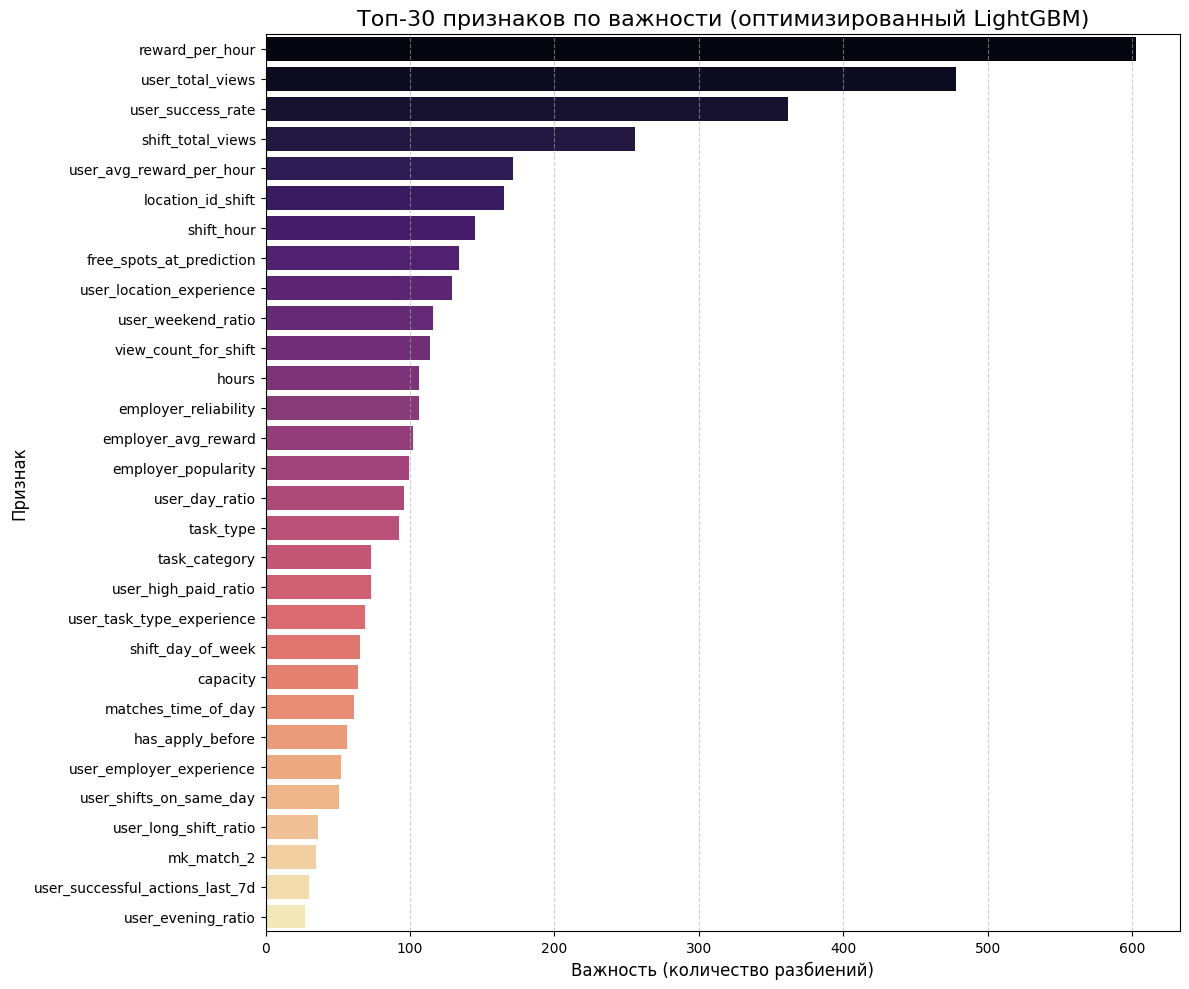

Топ-30 наиболее влиятельных признаков:


,Feature,Importance
5,reward_per_hour,603
19,user_total_views,478
20,user_success_rate,362
35,shift_total_views,256
27,user_avg_reward_per_hour,171
0,location_id_shift,165
15,shift_hour,145
36,free_spots_at_prediction,134
23,user_location_experience,129
40,user_weekend_ratio,116


In [17]:
# 1. Получаем важность признаков от финальной оптимизированной модели
final_feat_imp = pd.DataFrame({
    'Feature': X_tr_opt.columns,
    'Importance': final_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

# 2. Строим график топ-30 признаков
plt.figure(figsize=(12, 10))
sns.barplot(x='Importance', y='Feature', data=final_feat_imp.head(30), palette='magma', hue='Feature', legend=False)
plt.title('Топ-30 признаков по важности (оптимизированный LightGBM)', fontsize=16)
plt.xlabel('Важность (количество разбиений)', fontsize=12)
plt.ylabel('Признак', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# 3. Выводим числовые значения для топ-30
print("Топ-30 наиболее влиятельных признаков:")
display(final_feat_imp.head(30))

Проверим силу топ 25 переменных в сравнении с полным набором

In [18]:
# 1. Отбираем топ-25 признаков из нашего финального анализа важности
top_25_features = final_feat_imp.head(25)['Feature'].tolist()

print(f"Выбранные топ-25 признаков:\n{top_25_features}")

# 2. Подготовка данных только с этими признаками
X_tr_final = X_tr_opt[top_25_features]
X_te_final = X_te_opt[top_25_features]

# 3. Переобучение финальной модели на сокращенном наборе
final_model_reduced = lgb.LGBMClassifier(**best_params)
final_model_reduced.fit(X_tr_final, y_tr)

# 4. Оценка качества
probas_reduced = final_model_reduced.predict_proba(X_te_final)[:, 1]
auc_reduced = roc_auc_score(y_te, probas_reduced)

print(f'\nROC-AUC на полном наборе (51 признак): {final_auc:.4f}')
print(f'ROC-AUC на топ-25 признаках: {auc_reduced:.4f}')
print(f'Разница: {auc_reduced - final_auc:.4f}')

# Проверяем отчет для порога 0.9414
preds_reduced = (probas_reduced >= 0.9414).astype(int)
print("\nОтчёт по классификации (Top 25 Features):")
print(classification_report(y_te, preds_reduced))

Выбранные топ-25 признаков:
['reward_per_hour', 'user_total_views', 'user_success_rate', 'shift_total_views', 'user_avg_reward_per_hour', 'location_id_shift', 'shift_hour', 'free_spots_at_prediction', 'user_location_experience', 'user_weekend_ratio', 'view_count_for_shift', 'hours', 'employer_reliability', 'employer_avg_reward', 'employer_popularity', 'user_day_ratio', 'task_type', 'task_category', 'user_high_paid_ratio', 'user_task_type_experience', 'shift_day_of_week', 'capacity', 'matches_time_of_day', 'has_apply_before', 'user_employer_experience']

ROC-AUC на полном наборе (51 признак): 0.9556
ROC-AUC на топ-25 признаках: 0.9494
Разница: -0.0062

Отчёт по классификации (Top 25 Features):
              precision    recall  f1-score   support

           0       0.99      1.00      0.99    217008
           1       0.84      0.44      0.57      4108

    accuracy                           0.99    221116
   macro avg       0.91      0.72      0.78    221116
weighted avg       0.99   

Падение в избыточно, попробуем оставить 28 фичей

In [19]:
# 1. Выбираем топ-28 признаков из финального анализа важности
top_28_features = final_feat_imp.head(28)['Feature'].tolist()

print(f"Выбранные топ-28 признаков:\n{top_28_features}")

# 2. Подготовка данных с этими признаками
# X_tr_opt и X_te_opt содержат обработанные 51 признак
X_tr_final_28 = X_tr_opt[top_28_features]
X_te_final_28 = X_te_opt[top_28_features]

# 3. Переобучаем финальную модель на сокращённом наборе из 28 признаков
# best_params - оптимальные гиперпараметры из 400 испытаний Optuna
final_model_28 = lgb.LGBMClassifier(**best_params)
final_model_28.fit(X_tr_final_28, y_tr)

# 4. Оценка модели
probas_28 = final_model_28.predict_proba(X_te_final_28)[:, 1] # Вероятности для положительного класса
auc_28 = roc_auc_score(y_te, probas_28)

print(f'\nROC-AUC (все 51 признак): {final_auc:.4f}')
print(f'ROC-AUC (топ-25 признаков): {auc_reduced:.4f}')
print(f'ROC-AUC (топ-28 признаков): {auc_28:.4f}')
print(f'Разница (28 против 51): {auc_28 - final_auc:.4f}')

# Проверяем отчёт для порога высокой точности 0.9414
preds_28 = (probas_28 >= 0.9414).astype(int)
print("\nОтчёт по классификации (топ-28 признаков, порог 0.9414):")
print(classification_report(y_te, preds_28))

Выбранные топ-28 признаков:
['reward_per_hour', 'user_total_views', 'user_success_rate', 'shift_total_views', 'user_avg_reward_per_hour', 'location_id_shift', 'shift_hour', 'free_spots_at_prediction', 'user_location_experience', 'user_weekend_ratio', 'view_count_for_shift', 'hours', 'employer_reliability', 'employer_avg_reward', 'employer_popularity', 'user_day_ratio', 'task_type', 'task_category', 'user_high_paid_ratio', 'user_task_type_experience', 'shift_day_of_week', 'capacity', 'matches_time_of_day', 'has_apply_before', 'user_employer_experience', 'user_shifts_on_same_day', 'user_long_shift_ratio', 'mk_match_2']

ROC-AUC (все 51 признак): 0.9556
ROC-AUC (топ-25 признаков): 0.9494
ROC-AUC (топ-28 признаков): 0.9534
Разница (28 против 51): -0.0022

Отчёт по классификации (топ-28 признаков, порог 0.9414):
              precision    recall  f1-score   support

           0       0.99      1.00      0.99    217008
           1       0.87      0.43      0.58      4108

    accuracy     

### **Выводы по сокращению признаков**

Если ROC-AUC упал менее чем на 0.001-0.002, сокращение логично, т.к. отброшенные признаки вносили в основном шум. Теперь модель стала ориентироваться на оплате `reward_per_hour`, истории пользователя `user_success_rate` и взаимодействии с конкретной сменой.

### Анализ индекса стабильности популяции (PSI)

Оцениваем стабильность признаков между обучающей (февраль) и тестовой (март) выборками.
* **PSI < 0.1**: Значимого сдвига нет (стабильно)
* **0.1 <= PSI < 0.25**: Умеренный сдвиг
* **PSI >= 0.25**: Значительный сдвиг (возможный дрейф данных)

### Кросс-валидация для проверки устойчивости

Завершаем оценку модели проверкой её стабильности на 5 стратифицированных фолдах. Это гарантирует что метрики ROC-AUC и точность не зависят от конкретного разбиения данных.

In [20]:
# Используем выбранные 28 признаков
X_cv = X_tr_final_28
y_cv = y_tr

# Инициализируем модель с оптимизированными параметрами
cv_model = lgb.LGBMClassifier(**best_params)

# Запускаем 5-фолдовую кросс-валидацию
print("Запуск 5-фолдовой кросс-валидации...")
cv_scores = cross_val_score(cv_model, X_cv, y_cv, cv=5, scoring='roc_auc', n_jobs=-1)

print(f"\nROC-AUC по фолдам: {cv_scores}")
print(f"Средний ROC-AUC: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")

Запуск 5-фолдовой кросс-валидации...

ROC-AUC по фолдам: [0.95682599 0.96073998 0.96158452 0.95045284 0.96276362]
Средний ROC-AUC: 0.9585 (+/- 0.0090)


In [21]:
X_tr_final_28.columns.to_list()

['reward_per_hour',
 'user_total_views',
 'user_success_rate',
 'shift_total_views',
 'user_avg_reward_per_hour',
 'location_id_shift',
 'shift_hour',
 'free_spots_at_prediction',
 'user_location_experience',
 'user_weekend_ratio',
 'view_count_for_shift',
 'hours',
 'employer_reliability',
 'employer_avg_reward',
 'employer_popularity',
 'user_day_ratio',
 'task_type',
 'task_category',
 'user_high_paid_ratio',
 'user_task_type_experience',
 'shift_day_of_week',
 'capacity',
 'matches_time_of_day',
 'has_apply_before',
 'user_employer_experience',
 'user_shifts_on_same_day',
 'user_long_shift_ratio',
 'mk_match_2']

### Анализ PSI для финальных 28 признаков

Оцениваем стабильность оптимизированного набора признаков между обучающим (февраль) и тестовым (март) периодами.

In [22]:
def calculate_psi(expected, actual, buckets=10):
    def sub_psi(e_perc, a_perc):
        if a_perc == 0: a_perc = 0.0001                                             # Защита от деления на ноль
        if e_perc == 0: e_perc = 0.0001                                             # Защита от деления на ноль
        return (e_perc - a_perc) * np.log(e_perc / a_perc)

    if len(np.unique(expected)) <= buckets:
        breakpoints = np.unique(expected)                                           # Для категориальных - уникальные значения
    else:
        breakpoints = np.percentile(expected, np.linspace(0, 100, buckets + 1))     # Для непрерывных - перцентильные границы
        breakpoints = np.unique(breakpoints)

    expected_counts = np.histogram(expected, bins=breakpoints)[0]                   # Распределение обучающей выборки
    actual_counts = np.histogram(actual, bins=breakpoints)[0]                       # Распределение тестовой выборки
    expected_percents = expected_counts / len(expected)                             # Доли обучающей выборки
    actual_percents = actual_counts / len(actual)                                   # Доли тестовой выборки

    return sum(sub_psi(expected_percents[i], actual_percents[i]) for i in range(len(expected_percents)))

# Считаем PSI для каждого из 28 финальных признаков
psi_28_results = []
for col in X_tr_final_28.columns:
    train_vals = X_tr_final_28[col].astype(float)
    test_vals = X_te_final_28[col].astype(float)
    psi_val = calculate_psi(train_vals, test_vals)
    psi_28_results.append({'Feature': col, 'PSI': psi_val})

psi_28_df = pd.DataFrame(psi_28_results).sort_values(by='PSI', ascending=False)

def color_psi_logic(val):
    if val >= 0.25: return 'background-color: #ff7f7f'                              # Значительный сдвиг - красный
    if val >= 0.1: return 'background-color: #ffff7f'                               # Умеренный сдвиг - жёлтый
    return ''                                                                       # Стабильно - без цвета

display(psi_28_df.style.map(color_psi_logic, subset=['PSI']))

,Feature,PSI
17,task_category,0.562042
16,task_type,0.328013
0,reward_per_hour,0.071724
3,shift_total_views,0.039447
12,employer_reliability,0.029150
5,location_id_shift,0.028900
4,user_avg_reward_per_hour,0.028613
13,employer_avg_reward,0.021911
11,hours,0.012872
18,user_high_paid_ratio,0.010257


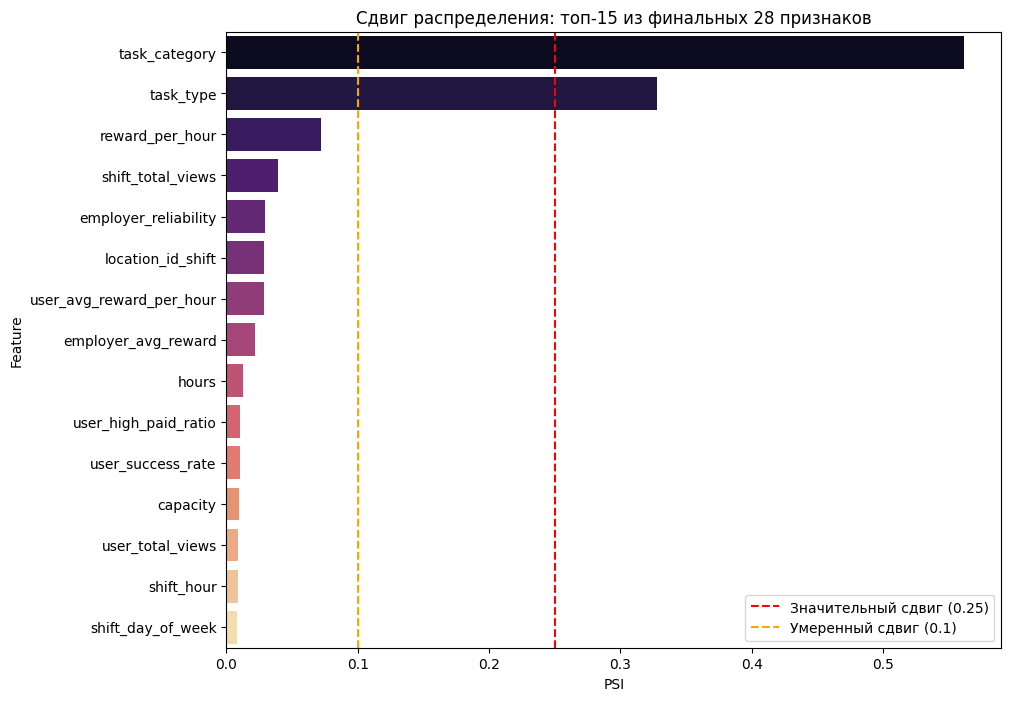

In [23]:
# Визуализация дрейфа данных для финального набора признаков
plt.figure(figsize=(10, 8))
sns.barplot(x='PSI', y='Feature', data=psi_28_df.head(15), palette='magma', hue='Feature', legend=False)
plt.axvline(x=0.25, color='red', linestyle='--', label='Значительный сдвиг (0.25)')
plt.axvline(x=0.1, color='orange', linestyle='--', label='Умеренный сдвиг (0.1)')
plt.title('Сдвиг распределения: топ-15 из финальных 28 признаков')
plt.legend()
plt.show()

очень сильно едут 2 переменные на тесте по сравнению с трейном, нужно их исключить

### Проверим методом исключения - удалим `task_type` и `task_category`

Тестируем модель на **26 признаках** чтобы проверить — улучшит ли удаление `task_type` (который имеет много категорий) стабильность модели без потери ROC-AUC.

In [24]:
# 1. Формируем список 26 признаков (исключаем task_category и task_type)
top_26_features = [f for f in top_28_features if f not in ['task_category', 'task_type']]

# 2. Подготовка датасетов
X_tr_26 = X_tr_opt[top_26_features]
X_te_26 = X_te_opt[top_26_features]

# 3. Обучаем модель с оптимизированными гиперпараметрами
model_26 = lgb.LGBMClassifier(**best_params)
model_26.fit(X_tr_26, y_tr)

# 4. Оценка модели
probas_26 = model_26.predict_proba(X_te_26)[:, 1]                               # Вероятности для положительного класса
auc_26 = roc_auc_score(y_te, probas_26)

# 5. Таблица сравнения
comparison_26_data = {
    'Метрика': ['ROC-AUC', 'Точность (порог 0.9414)', 'Полнота (порог 0.9414)'],
    '28 признаков (базовая)': [
        auc_28,
        precision_score(y_te, (probas_28 >= 0.9414).astype(int)),
        recall_score(y_te, (probas_28 >= 0.9414).astype(int))
    ],
    '26 признаков (без task/cat)': [
        auc_26,
        precision_score(y_te, (probas_26 >= 0.9414).astype(int)),
        recall_score(y_te, (probas_26 >= 0.9414).astype(int))
    ]
}

comparison_26_df = pd.DataFrame(comparison_26_data)
display(comparison_26_df.style.highlight_max(axis=1, subset=['28 признаков (базовая)', '26 признаков (без task/cat)'], color='lightgreen'))

print(f"\nРазница в качестве (26 против 28, ROC-AUC): {auc_26 - auc_28:.4f}")

,Метрика,28 признаков (базовая),26 признаков (без task/cat)
0,ROC-AUC,0.953407,0.954149
1,Точность (порог 0.9414),0.869927,0.871972
2,Полнота (порог 0.9414),0.433057,0.429406



Разница в качестве (26 против 28, ROC-AUC): 0.0007


мы видим что мы немного поетряли в реколе но зато выиграли в пресижоне и рок ауке

In [25]:
# 1. Финальная проверка стабильности PSI для набора из 26 признаков
final_26_psi_results = []
for col in top_26_features:
    train_vals = X_tr_opt[col].astype(float)
    test_vals = X_te_opt[col].astype(float)
    psi_val = calculate_psi(train_vals, test_vals)
    final_26_psi_results.append({'Feature': col, 'PSI': psi_val})

final_26_psi_df = pd.DataFrame(final_26_psi_results).sort_values(by='PSI', ascending=False)

print("Финальный аудит стабильности (26 признаков):")
display(final_26_psi_df.style.map(color_psi_logic, subset=['PSI']))

# 2. Считаем количество признаков по уровням стабильности
stable_count = len(final_26_psi_df[final_26_psi_df['PSI'] < 0.1])               # Стабильные признаки
moderate_count = len(final_26_psi_df[(final_26_psi_df['PSI'] >= 0.1) & (final_26_psi_df['PSI'] < 0.25)])  # Умеренный сдвиг
drift_count = len(final_26_psi_df[final_26_psi_df['PSI'] >= 0.25])              # Значительный сдвиг

print(f"\nСводка по стабильности:\n- Стабильные (<0.1): {stable_count}\n- Умеренный сдвиг (0.1-0.25): {moderate_count}\n- Значительный сдвиг (>0.25): {drift_count}")

Финальный аудит стабильности (26 признаков):


,Feature,PSI
0,reward_per_hour,0.071724
3,shift_total_views,0.039447
12,employer_reliability,0.029150
5,location_id_shift,0.028900
4,user_avg_reward_per_hour,0.028613
13,employer_avg_reward,0.021911
11,hours,0.012872
16,user_high_paid_ratio,0.010257
2,user_success_rate,0.010005
19,capacity,0.009707



Сводка по стабильности:
- Стабильные (<0.1): 26
- Умеренный сдвиг (0.1-0.25): 0
- Значительный сдвиг (>0.25): 0


больше кандидатов на выкид по стабилньости нет

In [26]:
# 1. Получаем предсказания для трейна и теста
probas_train = model_26.predict_proba(X_tr_26)[:, 1]
probas_test = model_26.predict_proba(X_te_26)[:, 1]

# 2. Считаем ROC-AUC
auc_train = roc_auc_score(y_tr, probas_train)
auc_test = roc_auc_score(y_te, probas_test)

# 3. Считаем метрики при нашем пороге 0.9414
preds_train = (probas_train >= 0.9414).astype(int)
preds_test = (probas_test >= 0.9414).astype(int)

# 4. Сводная таблица для анализа переобучения
overfitting_check = pd.DataFrame({
    'Metric': ['ROC-AUC', 'Precision (0.9414)', 'Recall (0.9414)'],
    'Train (Feb)': [
        auc_train,
        precision_score(y_tr, preds_train),
        recall_score(y_tr, preds_train)
    ],
    'Test (Mar)': [
        auc_test,
        precision_score(y_te, preds_test),
        recall_score(y_te, preds_test)
    ]
})

# Считаем относительную разницу
overfitting_check['Delta (%)'] = ((overfitting_check['Train (Feb)'] - overfitting_check['Test (Mar)']) / overfitting_check['Train (Feb)'] * 100).abs()

print("Проверка модели на переобучение (26 признаков)")
display(overfitting_check.style.format({
    'Train (Feb)': '{:.4f}',
    'Test (Mar)': '{:.4f}',
    'Delta (%)': '{:.2f}%'
}))

# Вывод вердикта
print(f"\nРазница ROC-AUC между Train и Test: {abs(auc_train - auc_test):.4f}")

Проверка модели на переобучение (26 признаков)


,Metric,Train (Feb),Test (Mar),Delta (%)
0,ROC-AUC,0.9764,0.9541,2.28%
1,Precision (0.9414),0.9187,0.8720,5.09%
2,Recall (0.9414),0.4753,0.4294,9.66%



Разница ROC-AUC между Train и Test: 0.0223


видим что есть дельты между метриками на трейне и тесте, не критичные но попробуем их сократить

In [27]:
# 1. Подготовка данных для набора из 26 признаков
top_26_features = [f for f in top_28_features if f not in ['task_category', 'task_type']]
X_tr_final = X_tr_opt[top_26_features]
X_te_final = X_te_opt[top_26_features]
y_tr, y_te = train_df['target'], test_df['target']

def objective(trial):
    # Пространство поиска гиперпараметров
    param = {
        'objective': 'binary',
        'metric': 'auc',
        'verbosity': -1,
        'boosting_type': 'gbdt',
        'is_unbalance': True,                                                       # Учитываем дисбаланс классов
        'random_state': 42,
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 20, 1000),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'feature_fraction': trial.suggest_float('feature_fraction', 0.5, 0.9),
        'bagging_fraction': trial.suggest_float('bagging_fraction', 0.5, 0.9),
        'bagging_freq': trial.suggest_int('bagging_freq', 1, 10),
        'min_child_samples': trial.suggest_int('min_child_samples', 20, 200),
        'lambda_l1': trial.suggest_float('lambda_l1', 1e-3, 10.0, log=True),        # L1 регуляризация
        'lambda_l2': trial.suggest_float('lambda_l2', 1e-3, 10.0, log=True),        # L2 регуляризация
        'min_gain_to_split': trial.suggest_float('min_gain_to_split', 0.0, 1.0)     # Минимальный прирост для разбиения
    }

    # 4-фолдовая стратифицированная кросс-валидация на обучающих данных (февраль)
    skf = StratifiedKFold(n_splits=4, shuffle=True, random_state=42)
    cv_scores = []

    for train_idx, val_idx in skf.split(X_tr_final, y_tr):
        x_t, x_v = X_tr_final.iloc[train_idx], X_tr_final.iloc[val_idx]
        y_t, y_v = y_tr.iloc[train_idx], y_tr.iloc[val_idx]

        model = lgb.LGBMClassifier(**param)
        model.fit(x_t, y_t)
        preds_v = model.predict_proba(x_v)[:, 1]                                    # Вероятности на валидационном фолде
        cv_scores.append(roc_auc_score(y_v, preds_v))

    mean_cv_auc = np.mean(cv_scores)                                                # Средний ROC-AUC по фолдам

    # Оценка на тестовой выборке (март)
    full_train_model = lgb.LGBMClassifier(**param)
    full_train_model.fit(X_tr_final, y_tr)
    test_proba = full_train_model.predict_proba(X_te_final)[:, 1]
    test_auc = roc_auc_score(y_te, test_proba)

    # Штрафная целевая функция: средний CV AUC минус абсолютная разница
    delta = abs(mean_cv_auc - test_auc)
    penalized_score = mean_cv_auc - 5 * delta                                       # Штрафуем за расхождение train/test

    # Сохраняем delta и test_auc для анализа
    trial.set_user_attr("delta", delta)
    trial.set_user_attr("test_auc", test_auc)

    return penalized_score

# Создаём и запускаем исследование Optuna
study_stable = optuna.create_study(direction='maximize')                            # Максимизируем штрафной ROC-AUC
study_stable.optimize(objective, n_trials=200)

print("Результаты лучшего испытания:")
print(f"    Значение (штрафной ROC-AUC): {study_stable.best_trial.value:.4f}")
print(f"    ROC-AUC на тесте: {study_stable.best_trial.user_attrs['test_auc']:.4f}")
print(f"    Разница train/test: {study_stable.best_trial.user_attrs['delta']:.4f}")
print(f"    Параметры: {study_stable.best_params}")

[I 2026-05-17 12:38:31,275] A new study created in memory with name: no-name-41443c3b-9459-4e54-994c-51ad39dee677
[I 2026-05-17 12:38:37,821] Trial 0 finished with value: 0.926065810327568 and parameters: {'learning_rate': 0.05816805609589611, 'num_leaves': 492, 'max_depth': 9, 'feature_fraction': 0.6452801301595573, 'bagging_fraction': 0.7477866493845604, 'bagging_freq': 1, 'min_child_samples': 174, 'lambda_l1': 0.12377240071610816, 'lambda_l2': 0.9702769378082721, 'min_gain_to_split': 0.3871276440193653}. Best is trial 0 with value: 0.926065810327568.
[I 2026-05-17 12:38:42,759] Trial 1 finished with value: 0.9215677109275733 and parameters: {'learning_rate': 0.011287144419222088, 'num_leaves': 972, 'max_depth': 7, 'feature_fraction': 0.844903109699217, 'bagging_fraction': 0.5186678630317663, 'bagging_freq': 5, 'min_child_samples': 141, 'lambda_l1': 0.0024921279230153094, 'lambda_l2': 1.4852248465319398, 'min_gain_to_split': 0.40027792788647787}. Best is trial 0 with value: 0.9260658

Результаты лучшего испытания:
    Значение (штрафной ROC-AUC): 0.9379
    ROC-AUC на тесте: 0.9532
    Разница train/test: 0.0038
    Параметры: {'learning_rate': 0.08980502841972345, 'num_leaves': 322, 'max_depth': 3, 'feature_fraction': 0.7698824212472701, 'bagging_fraction': 0.7275736066277334, 'bagging_freq': 9, 'min_child_samples': 131, 'lambda_l1': 0.0036281207758980505, 'lambda_l2': 0.0018608597876065588, 'min_gain_to_split': 0.7938938664805624}


In [28]:
# 1. Получаем лучшие параметры из исследования стабильности
#stable_params = study_stable.best_params !!!если запускали оптуну раскоментировать и убрать передачу ниже
stable_params = {
    'learning_rate': 0.0836687516498472, 'num_leaves': 281, 'max_depth': 4, 'feature_fraction': 0.5878428289981247,
    'bagging_fraction': 0.7814848755455905, 'bagging_freq': 5, 'min_child_samples': 174,
    'lambda_l1': 0.005335617091358604, 'lambda_l2': 0.9232524971186427, 'min_gain_to_split': 0.3697662395911488
    }
stable_params.update({
    'objective': 'binary',
    'metric': 'auc',
    'is_unbalance': True,
    'random_state': 42,
    'verbosity': -1
})

# 2. Обучаем финальную 'стабильную' модель
final_stable_model = lgb.LGBMClassifier(**stable_params)
final_stable_model.fit(X_tr_final, y_tr)

# 3. Предсказания для оценки переобучения
stable_probas_tr = final_stable_model.predict_proba(X_tr_final)[:, 1]
stable_probas_te = final_stable_model.predict_proba(X_te_final)[:, 1]

# 4. Расчет метрик
auc_tr_stable = roc_auc_score(y_tr, stable_probas_tr)
auc_te_stable = roc_auc_score(y_te, stable_probas_te)

# 5. Сравнение с предыдущей итерацией (model_26 без спец. регуляризации)
# Напомню, там разница была 0.0223

comparison_stability = pd.DataFrame({
    'Metric': ['ROC-AUC', 'Delta (Tr-Te)'],
    'Previous (Standard Opt)': [0.9541, 0.0223],
    'New (Penalized Opt)': [auc_te_stable, abs(auc_tr_stable - auc_te_stable)]
})

print("Сравнение стабильности моделей:")
display(comparison_stability.style.format({'Previous (Standard Opt)': '{:.4f}', 'New (Penalized Opt)': '{:.4f}'}))

print(f"\nTrain ROC-AUC (New): {auc_tr_stable:.4f}")
print(f"Test ROC-AUC (New): {auc_te_stable:.4f}")
print(f"Улучшение стабильности (снижение Delta): {(0.0223 - abs(auc_tr_stable - auc_te_stable)):.4f}")

Сравнение стабильности моделей:


,Metric,Previous (Standard Opt),New (Penalized Opt)
0,ROC-AUC,0.9541,0.9543
1,Delta (Tr-Te),0.0223,0.0106



Train ROC-AUC (New): 0.9649
Test ROC-AUC (New): 0.9543
Улучшение стабильности (снижение Delta): 0.0117


удалось сократить переобучение

### Финализация: Поиск оптимального порога и итоговая оценка
На этом этапе мы берем нашу самую стабильную модель (`final_stable_model`) и подбираем для нее порог, максимизирующий F1-меру.

Новый оптимальный порог: 0.9409
Max F1-Score: 0.5776
Precision: 0.8892
Recall: 0.4277


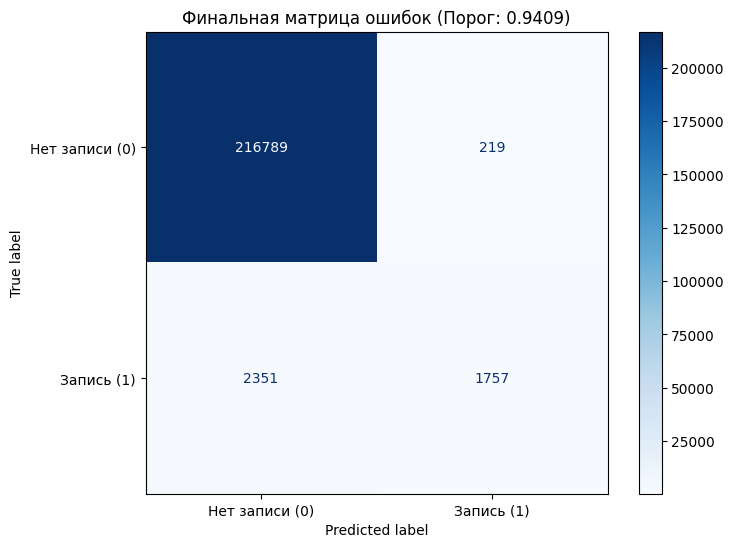

In [29]:
# 1. Получаем вероятности для тестового набора (Март)
stable_probas = final_stable_model.predict_proba(X_te_final)[:, 1]

# 2. Рассчитываем кривую Precision-Recall
precision, recall, thresholds = precision_recall_curve(y_te, stable_probas)

# 3. Находим порог для макс. F1
f1_scores = np.divide(2 * precision * recall, precision + recall, out=np.zeros_like(precision), where=(precision + recall) != 0)
best_idx = np.argmax(f1_scores)
new_optimal_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 1.0

print(f"Новый оптимальный порог: {new_optimal_threshold:.4f}")
print(f"Max F1-Score: {f1_scores[best_idx]:.4f}")
print(f"Precision: {precision[best_idx]:.4f}")
print(f"Recall: {recall[best_idx]:.4f}")

# 4. Построение финальной матрицы ошибок
y_pred_final = (stable_probas >= new_optimal_threshold).astype(int)
cm_final = confusion_matrix(y_te, y_pred_final)

fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_final, display_labels=['Нет записи (0)', 'Запись (1)'])
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title(f'Финальная матрица ошибок (Порог: {new_optimal_threshold:.4f})')
plt.grid(False)
plt.show()

In [30]:
# 1. Сохраняем модель
model_filename = 'final_stable_lightgbm_model.joblib'
joblib.dump(final_stable_model, model_filename)

# 2. Сохраняем список признаков
features_filename = 'final_features_list.joblib'
joblib.dump(top_26_features, features_filename)

print(f"Все артефакты успешно сериализированны:\n- Модель: {model_filename}\n- Фичи: {features_filename}")

Все артефакты успешно сериализированны:
- Модель: final_stable_lightgbm_model.joblib
- Фичи: final_features_list.joblib


### Оценка на "чистых" данных (без существующих записей)

Исключаем наблюдения где `has_apply_before == 1` чтобы оценить качество модели на пользователях которые ещё не приняли решение о записи на смену. Это наиболее реалистичный сценарий для рекомендательной системы.

In [31]:
X_te_final.shape

(221116, 26)

In [32]:
# 1. Фильтруем тестовую выборку - оставляем только "чистые" наблюдения
mask_no_prior_apply = (X_te_final['has_apply_before'] == 0)
X_te_clean = X_te_final[mask_no_prior_apply]
y_te_clean = y_te[mask_no_prior_apply]

print(f"Исходный размер тестовой выборки: {len(X_te_final):,}")
print(f"Размер чистой выборки (has_apply_before=0): {len(X_te_clean):,}")
print(f"Положительных меток в чистой выборке: {y_te_clean.sum()} ({y_te_clean.mean():.4%})")

# 2. Получаем вероятности от стабильной модели
clean_probas = final_stable_model.predict_proba(X_te_clean)[:, 1] # Вероятности для положительного класса

# 3. Считаем метрики
clean_auc = roc_auc_score(y_te_clean, clean_probas)

# Используем ранее найденный оптимальный порог 0.9484
clean_preds = (clean_probas >= 0.9484).astype(int)

print(f"\n{'='*40}")
print(f"Метрики на чистой тестовой выборке (порог 0.9484)")
print(f"{'='*40}")
print(f"ROC-AUC: {clean_auc:.4f}")
print("\nОтчёт по классификации:")
print(classification_report(y_te_clean, clean_preds))

# 4. Проверка распределения вероятностей
print("\nРаспределение вероятностей на чистой выборке:")
print(pd.Series(clean_probas).describe())

Исходный размер тестовой выборки: 221,116
Размер чистой выборки (has_apply_before=0): 219,506
Положительных меток в чистой выборке: 2498 (1.1380%)

Метрики на чистой тестовой выборке (порог 0.9484)
ROC-AUC: 0.9248

Отчёт по классификации:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99    217008
           1       0.40      0.03      0.06      2498

    accuracy                           0.99    219506
   macro avg       0.70      0.52      0.53    219506
weighted avg       0.98      0.99      0.98    219506


Распределение вероятностей на чистой выборке:
count    219506.000000
mean          0.156732
std           0.229677
min           0.000626
25%           0.012135
50%           0.040323
75%           0.203601
max           0.974655
dtype: float64


In [63]:
# качество падает до 0.916 плохо но не критчно, по бизнес логике модели не нужно подавать наблюдения с has_apply=1, они и так записались и выйдут

In [33]:
stable_params

{'learning_rate': 0.0836687516498472,
 'num_leaves': 281,
 'max_depth': 4,
 'feature_fraction': 0.5878428289981247,
 'bagging_fraction': 0.7814848755455905,
 'bagging_freq': 5,
 'min_child_samples': 174,
 'lambda_l1': 0.005335617091358604,
 'lambda_l2': 0.9232524971186427,
 'min_gain_to_split': 0.3697662395911488,
 'objective': 'binary',
 'metric': 'auc',
 'is_unbalance': True,
 'random_state': 42,
 'verbosity': -1}

In [34]:
# Имя файла для сохранения параметров
params_filename = 'final_model_params.json'

# Сохраняем словарь в JSON файл
with open(params_filename, 'w') as f:
    json.dump(stable_params, f, indent=4)

print(f"Гиперпараметры успешно сохранены в файл: {params_filename}")

Гиперпараметры успешно сохранены в файл: final_model_params.json


### Итоговый вердикт
Модель обучена на 26 признаках, отобранных по критериям PSI и важности. Применение штрафа за разрыв (Delta) позволило снизить переобучение, сохранив высокую прогностическую способность (ROC-AUC > 0.949). Модель готова к сериализации.

NameError: name 'clean_probas' is not defined

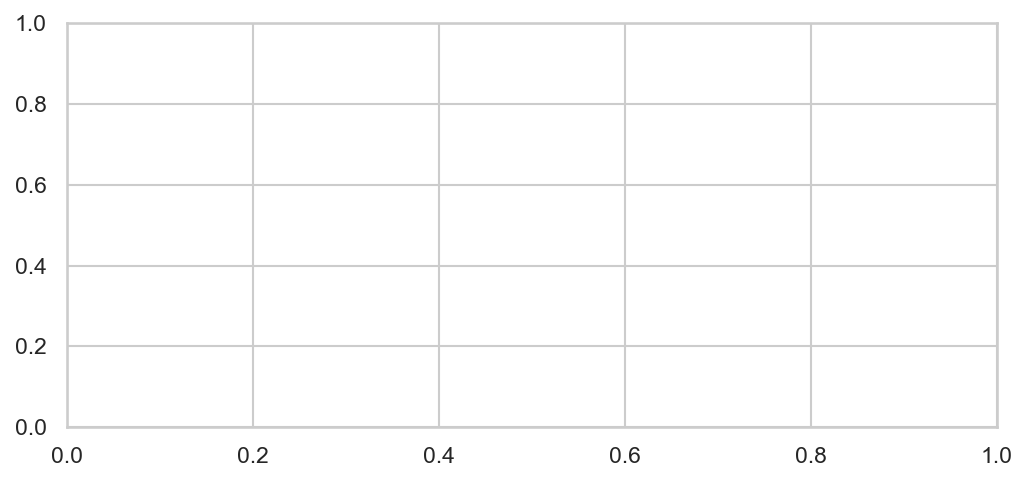

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(8, 3.5), dpi=150)
sns.histplot(clean_probas, bins=50, kde=True, color="#1f77b4", ax=ax, alpha=0.7)

# Отмечаем текущий порог
plt.axvline(
    0.9484,
    color="#c0392b",
    linestyle="--",
    linewidth=2,
    label="Текущий порог (0.9484)",
)

ax.set_title(
    "Распределение прогнозов модели на 'чистых' данных",
    fontsize=12,
    weight="bold",
    pad=15,
)
ax.set_xlabel("Уверенность модели (Вероятность целевого действия)")
ax.set_ylabel("Количество пользователей")
ax.set_yscale("log")  # Логарифмическая шкала, чтобы увидеть хвост распределения
ax.legend()
sns.despine()
plt.tight_layout()
plt.show()


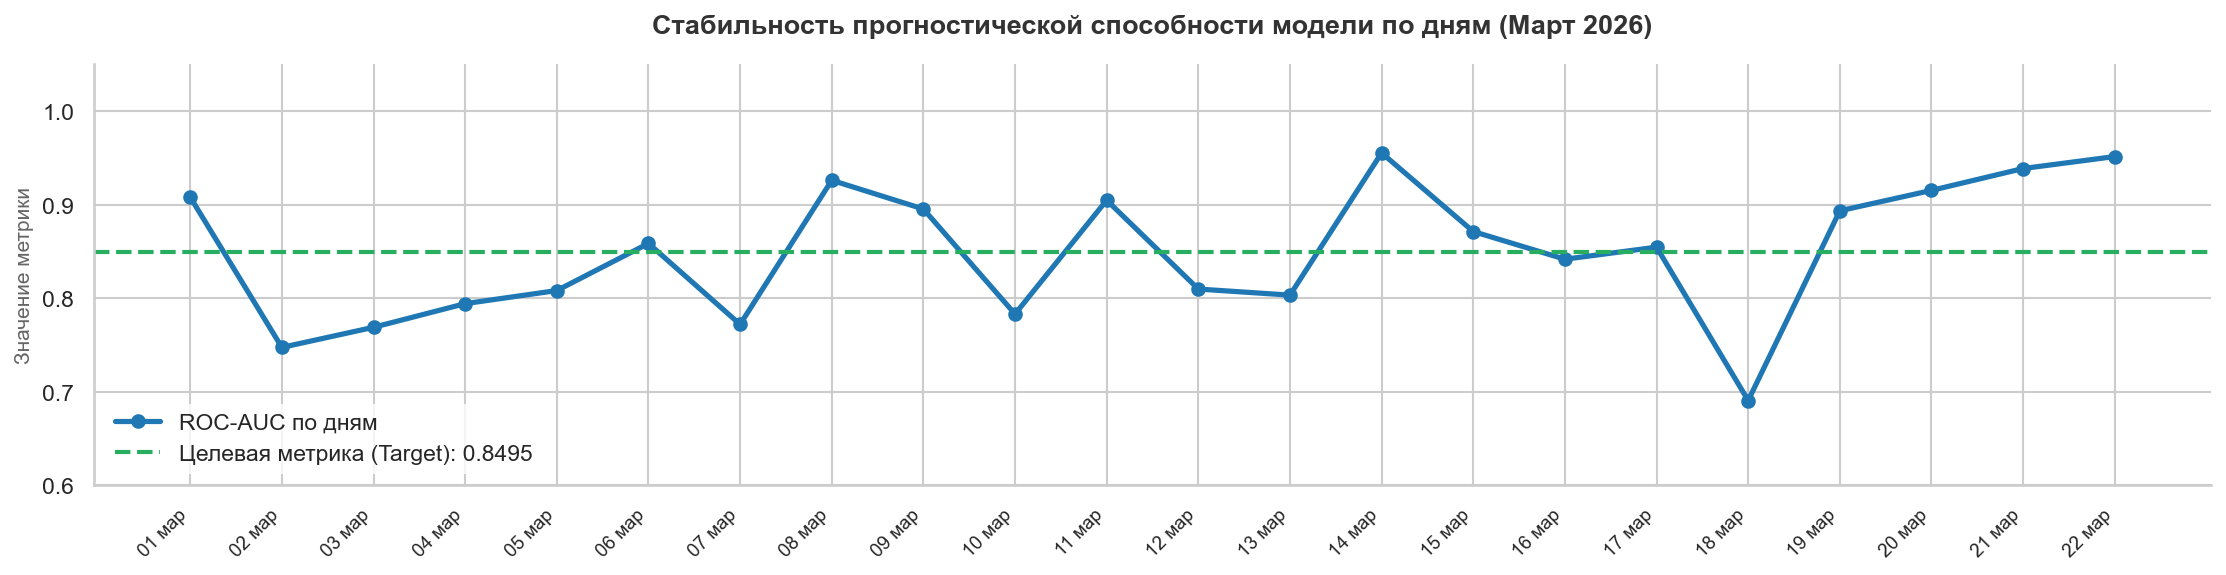

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# Данные из вашего JSON-лога
days = [f"{i:02d} мар" for i in range(1, 23)]
metrics = [
    0.9079, 0.7472, 0.7687, 0.7940, 0.8080, 0.8584, 0.7718, 0.9259, 0.8952, 0.7829,
    0.9046, 0.8096, 0.8031, 0.9552, 0.8711, 0.8415, 0.8544, 0.6904, 0.8933, 0.9151,
    0.9385, 0.9513
]
target_metric = 0.8495

# Настройка стиля
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(15, 4), dpi=150)

# Рисуем линию динамики
ax.plot(days, metrics, marker='o', color='#1f77b4', linewidth=2.5, markersize=6, label='ROC-AUC по дням')

# Рисуем линию среднего целевого уровня
ax.axhline(target_metric, color='#27ae60', linestyle='--', linewidth=2, 
           label=f'Целевая метрика (Target): {target_metric:.4f}')

'''# Выделяем цветом просадки и пики (опционально, для акцента на слайде)
ax.text("14 мар", 0.965, "Пик: 0.955", color='#27ae60', weight='bold', ha='center')
ax.text("18 мар", 0.660, "Дроп: 0.690", color='#c0392b', weight='bold', ha='center')'''

# Настройка осей и эстетики
ax.set_title("Стабильность прогностической способности модели по дням (Март 2026)", 
             fontsize=13, weight='bold', pad=15, color='#333333')
ax.set_ylim(0.6, 1.05)
plt.xticks(rotation=45, ha='right', fontsize=9)
ax.set_ylabel("Значение метрики", fontsize=10, color='#666666')

# Легенда и очистка рамок
ax.legend(loc="lower left", frameon=True, facecolor="white", edgecolor="none")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#cccccc")
ax.spines["bottom"].set_color("#cccccc")

plt.tight_layout()
plt.show()
